# Random Forest: Classification and Regression

**Aim:** Apply the Random Forest algorithm to one classification dataset and one regression dataset, and evaluate each with the appropriate metrics.

| Task | Dataset | Model | Metrics |
|---|---|---|---|
| Classification | Breast Cancer (569 samples, 30 features) | `RandomForestClassifier` | Accuracy score, confusion matrix |
| Regression | Diabetes (442 samples, 10 features) | `RandomForestRegressor` | R² score, mean squared error |

**What is a Random Forest?** It is an *ensemble* of many decision trees. Each tree is trained on a random bootstrap sample of the data and considers a random subset of features at each split. For classification the trees vote and the majority wins; for regression their predictions are averaged. This reduces the overfitting that a single decision tree suffers from.

## 1. Import libraries

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             confusion_matrix, mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split

# Part A: Classification

## 2. Load the Breast Cancer dataset
The target is binary: `0` = malignant, `1` = benign. The 30 features describe cell nucleus measurements (radius, texture, area, etc.).

In [2]:
cancer = load_breast_cancer()
print("Samples, features:", cancer.data.shape)
print("Classes:", dict(enumerate(cancer.target_names)))

Samples, features: (569, 30)
Classes: {0: np.str_('malignant'), 1: np.str_('benign')}


## 3. Train/test split
We hold out 20% of the data for testing so the model is evaluated on data it has never seen. `stratify` keeps the class proportions the same in both sets, and `random_state` makes the result reproducible.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, test_size=0.2, random_state=42, stratify=cancer.target)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


## 4. Train the Random Forest classifier
`n_estimators=100` builds a forest of 100 trees. No feature scaling is needed because trees split on thresholds.

In [4]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

## 5. Evaluate: accuracy score and confusion matrix
- **Accuracy** = correct predictions / total predictions.
- **Confusion matrix** shows, for each actual class (rows), how many samples were predicted as each class (columns). Diagonal cells are correct predictions; off-diagonal cells are errors.

Accuracy score: 0.956140350877193
Confusion matrix:
 [[39  3]
 [ 2 70]]


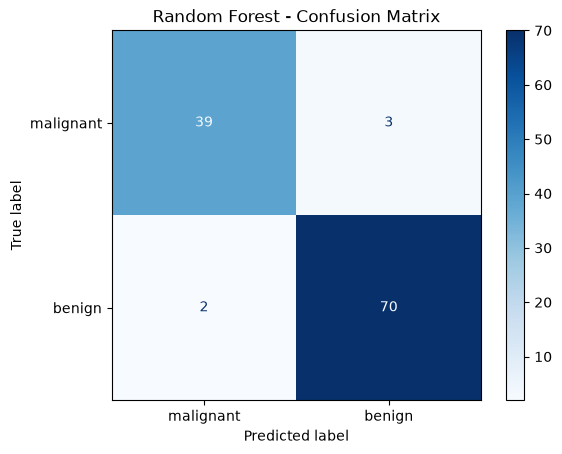

In [5]:
print("Accuracy score:", accuracy_score(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=cancer.target_names, cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation:** The model reaches about 95.6% accuracy on the test set. Of 114 test samples, 39 malignant and 70 benign cases were classified correctly; 3 malignant cases were wrongly predicted benign (false negatives) and 2 benign cases were wrongly predicted malignant (false positives). In a medical setting false negatives are the costlier error, so this is the number to watch.

# Part B: Regression

## 6. Load the Diabetes dataset
The target is a continuous number: a measure of disease progression one year after baseline. The 10 features are age, sex, BMI, blood pressure and six blood serum measurements (already normalised).

In [6]:
diabetes = load_diabetes()
print("Samples, features:", diabetes.data.shape)
print("Target range:", diabetes.target.min(), "to", diabetes.target.max())

Samples, features: (442, 10)
Target range: 25.0 to 346.0


## 7. Train/test split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    diabetes.data, diabetes.target, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (353, 10)  Test: (89, 10)


## 8. Train the Random Forest regressor
For regression, each tree predicts a number and the forest returns the **average** of all 100 predictions.

In [8]:
reg = RandomForestRegressor(n_estimators=100, random_state=42)
reg.fit(X_train, y_train)
y_pred = reg.predict(X_test)

## 9. Evaluate: R² score and mean squared error
- **R² score** is the fraction of the variance in the target that the model explains. 1.0 is perfect, 0 is no better than always predicting the mean.
- **Mean squared error (MSE)** is the average of the squared differences between predicted and actual values. Lower is better, and it is in squared units of the target.

R2 score: 0.4428225673999313
Mean squared error: 2952.0105887640448


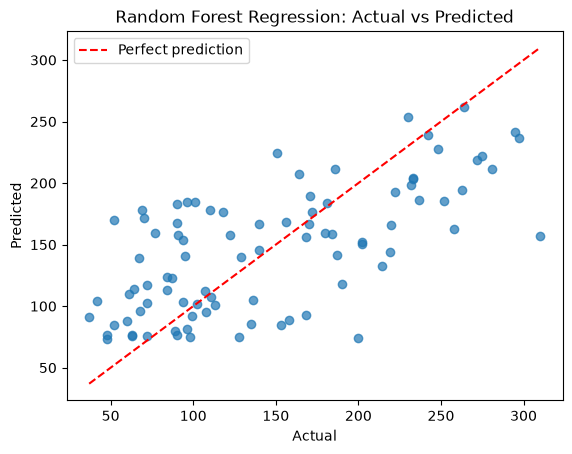

In [9]:
print("R2 score:", r2_score(y_test, y_pred))
print("Mean squared error:", mean_squared_error(y_test, y_pred))

plt.scatter(y_test, y_pred, alpha=0.7)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual"); plt.ylabel("Predicted")
plt.title("Random Forest Regression: Actual vs Predicted")
plt.legend(); plt.show()

**Interpretation:** R² is about 0.44, so the model explains roughly 44% of the variance in disease progression. This is modest, but expected: the Diabetes dataset is small (442 rows) and noisy, and even well-tuned models rarely exceed about 0.5 R² on it. The scatter plot shows the same thing: predictions follow the diagonal loosely but with wide spread.

## 10. Conclusion

| Task | Metric | Result |
|---|---|---|
| Classification | Accuracy | ≈ 0.956 |
| Classification | Confusion matrix | [[39, 3], [2, 70]] |
| Regression | R² | ≈ 0.443 |
| Regression | MSE | ≈ 2952 |

Random Forest works well out of the box on the cleanly separable Breast Cancer data and gives a moderate fit on the noisy Diabetes data. The same algorithm handles both tasks by switching between majority voting (classification) and averaging (regression).